# **Persiapan dan Upload Data**

In [ ]:
# ==========================================
# SEL 1: PERSIAPAN & UPLOAD DATA
# ==========================================
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Silakan upload file Excel Anda (3TIA_Kelompok10_Electricity Consumption.xlsx):")
uploaded = files.upload()

Silakan upload file Excel Anda (3TIA_Kelompok10_Electricity Consumption.xlsx):


Saving 3TIA_Kelompok10_Electricity Consumption.xlsx to 3TIA_Kelompok10_Electricity Consumption.xlsx


# **Statistika Deskriptif (Tabel & Grafik)**

--- A. Tabel Ringkasan Profil Penggunaan Listrik & Cuaca ---


,pemakaian_listrik,suhu_maksimal,curah_hujan
count,1433.000000,1433.000000,1433.000000
mean,1561.078061,17.187509,3.800488
std,606.819667,10.136415,10.973436
min,14.218000,-8.900000,0.000000
25%,1165.700000,8.900000,0.000000
50%,1542.650000,17.800000,0.000000
75%,1893.608000,26.100000,1.300000
max,4773.386000,39.400000,192.300000



--- B. Grafik Distribusi Pemakaian Listrik Harian ---


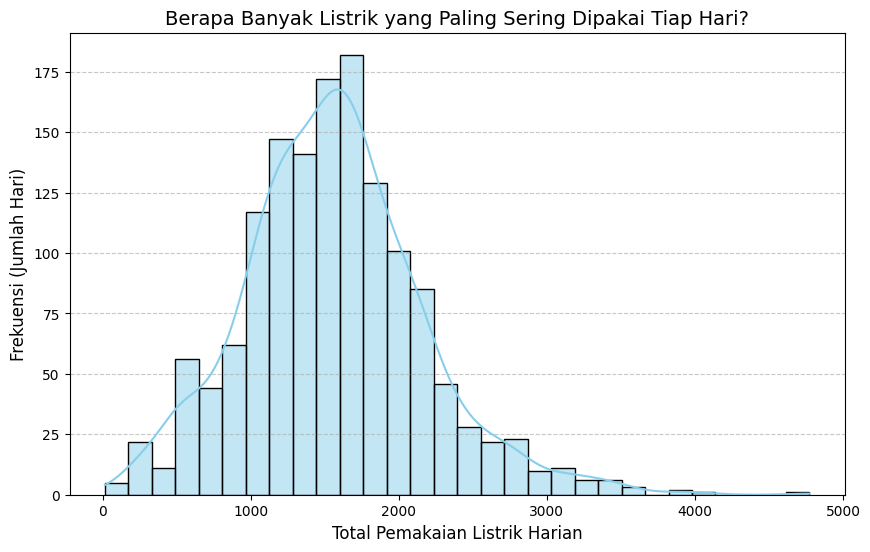

In [ ]:
# ==========================================
# SEL 2: STATISTIKA DESKRIPTIF
# ==========================================
# 1. Membaca data yang sudah di-upload
nama_file = "3TIA_Kelompok10_Electricity Consumption.xlsx"
data_utama = pd.read_excel(nama_file, sheet_name=0)

# 2. Mengubah nama variabel utama agar sangat mudah dibaca orang awam
data_utama = data_utama.rename(columns={
    'daily_consumption': 'pemakaian_listrik',
    'TMAX': 'suhu_maksimal',
    'PRCP': 'curah_hujan'
})

print("--- A. Tabel Ringkasan Profil Penggunaan Listrik & Cuaca ---")
# Menghitung statistik deskriptif
tabel_ringkasan = data_utama[['pemakaian_listrik', 'suhu_maksimal', 'curah_hujan']].describe()
# Menggunakan display() agar tampil sebagai tabel interaktif yang rapi dan bergaris
display(tabel_ringkasan)

print("\n--- B. Grafik Distribusi Pemakaian Listrik Harian ---")
# Membuat grafik (Histogram)
plt.figure(figsize=(10, 6))
sns.histplot(data_utama['pemakaian_listrik'], bins=30, kde=True, color='skyblue')
plt.title("Berapa Banyak Listrik yang Paling Sering Dipakai Tiap Hari?", fontsize=14)
plt.xlabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.ylabel("Frekuensi (Jumlah Hari)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# **Distribusi Probabilitas (Peluang & Kurva Normal)**

--- A. Peluang Terjadinya Peak Load (Hari Hujan vs Hari Cerah) ---
Batas pemakaian disebut Peak Load (Lonjakan) adalah di atas angka: 2291.30

1. Tabel Peluang Terjadinya Peak Load:


,Kondisi Cuaca,Peluang Peak Load (%)
0,Hari Hujan,11.600000
1,Hari Cerah,9.217578


/tmp/ipykernel_2021/180416253.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, palette=warna_bar)


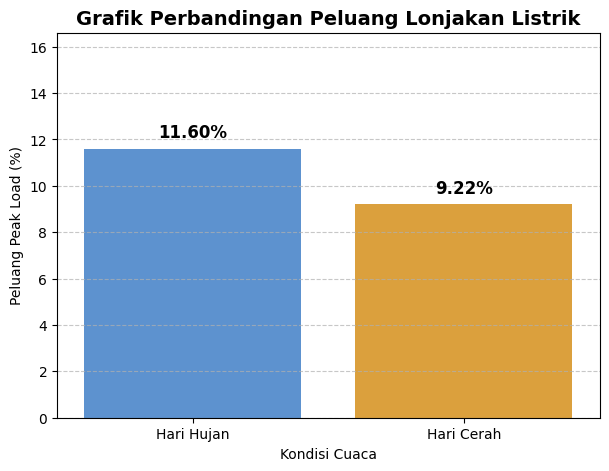



--- B. Pengecekan Kurva Normal pada Konsumsi Listrik ---


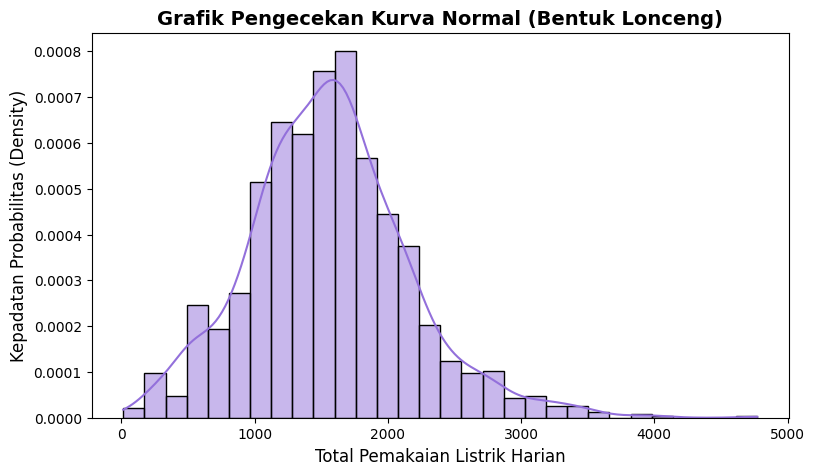


Analisis Kesimpulan Uji Normalitas:
- Nilai P-Value: 1.4272481028863604e-12
- Kesimpulan: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan pola pada grafik di atas).


In [ ]:
# ==========================================
# SEL 3: DISTRIBUSI PROBABILITAS (TABEL, ANALISIS, & GRAFIK)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("--- A. Peluang Terjadinya Peak Load (Hari Hujan vs Hari Cerah) ---")

# Kita tentukan "Peak Load" (Lonjakan) adalah jika listrik masuk di 10% pemakaian tertinggi
batas_lonjakan = data_utama['pemakaian_listrik'].quantile(0.90)

hari_hujan = data_utama[data_utama['curah_hujan'] > 0]
hari_cerah = data_utama[data_utama['curah_hujan'] == 0]

peluang_hujan = (len(hari_hujan[hari_hujan['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_hujan)) * 100
peluang_cerah = (len(hari_cerah[hari_cerah['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_cerah)) * 100

# 1. Membuat TABEL Probabilitas
tabel_peluang = pd.DataFrame({
    'Kondisi Cuaca': ['Hari Hujan', 'Hari Cerah'],
    'Peluang Peak Load (%)': [peluang_hujan, peluang_cerah]
})
print(f"Batas pemakaian disebut Peak Load (Lonjakan) adalah di atas angka: {batas_lonjakan:.2f}")
print("\n1. Tabel Peluang Terjadinya Peak Load:")
display(tabel_peluang) # Menampilkan tabel bergaris yang rapi

# 2. Membuat GRAFIK Bar Chart Probabilitas
plt.figure(figsize=(7, 5))
warna_bar = ['#4A90E2', '#F5A623']
sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, palette=warna_bar)

# Menambahkan angka persen di atas batang
for index, value in enumerate(tabel_peluang['Peluang Peak Load (%)']):
    plt.text(index, value + 0.3, f'{value:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.title("Grafik Perbandingan Peluang Lonjakan Listrik", fontsize=14, fontweight='bold')
plt.ylim(0, max(tabel_peluang['Peluang Peak Load (%)']) + 5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("\n===========================================================\n")
print("--- B. Pengecekan Kurva Normal pada Konsumsi Listrik ---")

# 3. Membuat GRAFIK Kurva Normal (Kurva Lonceng / Density Plot)
plt.figure(figsize=(9, 5))
sns.histplot(data_utama['pemakaian_listrik'], kde=True, stat="density", color='mediumpurple', bins=30)
plt.title("Grafik Pengecekan Kurva Normal (Bentuk Lonceng)", fontsize=14, fontweight='bold')
plt.xlabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.ylabel("Kepadatan Probabilitas (Density)", fontsize=12)
plt.show()

# 4. Membuat ANALISIS Teks Otomatis
nilai_statistik, p_value = stats.shapiro(data_utama['pemakaian_listrik'])
print("\nAnalisis Kesimpulan Uji Normalitas:")
print(f"- Nilai P-Value: {p_value}")
if p_value > 0.05:
    print("- Kesimpulan: Data pemakaian listrik TERDISTRIBUSI NORMAL (Membentuk kurva lonceng sempurna).")
else:
    print("- Kesimpulan: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan pola pada grafik di atas).")

# **Statistika Inferensial (Korelasi & Prediksi)**

--- A. Uji Korelasi Pearson (Hubungan Suhu dan Listrik) ---
1. Tabel Matriks Korelasi (Angka Hubungan):


,pemakaian_listrik,suhu_maksimal
pemakaian_listrik,1.000000,-0.525494
suhu_maksimal,-0.525494,1.000000


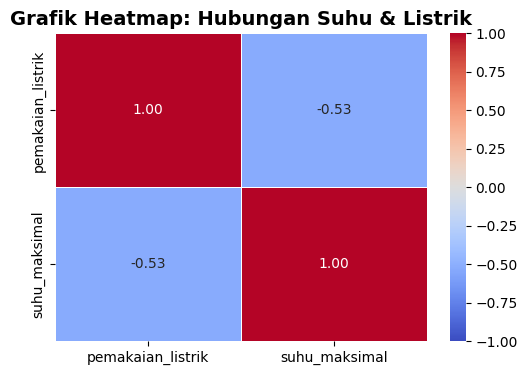


3. Analisis Kesimpulan Uji Korelasi Pearson:
- Nilai Kekuatan Hubungan: -0.53
- Nilai P-Value: 1.5263529550366167e-102
- Kesimpulan: Hubungannya NEGATIF. Artinya, makin DINGIN suhu cuaca, makin TINGGI pemakaian listrik.


--- B. Regresi Linear Sederhana (Prediksi Sederhana) ---

1. Analisis Rumus Prediksi:
Berdasarkan data, kita bisa membuat rumus tebakan masa depan:
Total Listrik = (-31.46 * Suhu) + 2101.78


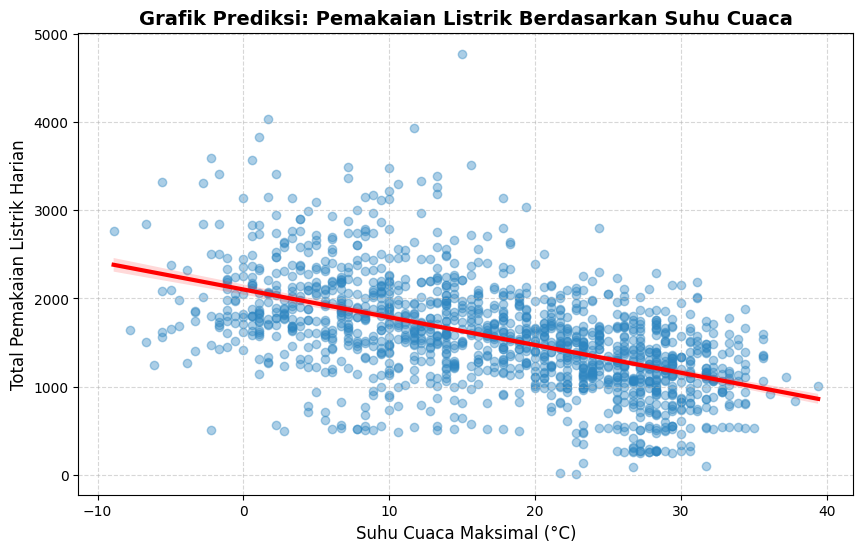


Cara membaca grafik: Garis merah yang menanjak naik membuktikan bahwa jika suhu bergerak memanas ke arah kanan, maka pemakaian listrik pasti akan bergerak naik ke atas.


In [ ]:
# ==========================================
# SEL 4: STATISTIKA INFERENSIAL (TABEL, ANALISIS, & GRAFIK)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("--- A. Uji Korelasi Pearson (Hubungan Suhu dan Listrik) ---")

# 1. Membuat TABEL Matriks Korelasi
# Kita fokus melihat hubungan antara Pemakaian Listrik dan Suhu Maksimal
tabel_korelasi = data_utama[['pemakaian_listrik', 'suhu_maksimal']].corr()
print("1. Tabel Matriks Korelasi (Angka Hubungan):")
display(tabel_korelasi)

# 2. Membuat GRAFIK Heatmap (Warna) dari Tabel Korelasi
plt.figure(figsize=(6, 4))
# Semakin merah/panas warnanya, semakin kuat hubungannya
sns.heatmap(tabel_korelasi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Grafik Heatmap: Hubungan Suhu & Listrik", fontsize=14, fontweight='bold')
plt.show()

# 3. ANALISIS Teks Otomatis (Uji Korelasi Pearson)
nilai_korelasi, p_value_korelasi = stats.pearsonr(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
print("\n3. Analisis Kesimpulan Uji Korelasi Pearson:")
print(f"- Nilai Kekuatan Hubungan: {nilai_korelasi:.2f}")
print(f"- Nilai P-Value: {p_value_korelasi}")

if nilai_korelasi > 0:
    print("- Kesimpulan: Hubungannya POSITIF dan SIGNIFIKAN. Artinya, secara ilmiah terbukti bahwa makin PANAS suhu cuaca, makin TINGGI pemakaian listrik rumah tangga.")
elif nilai_korelasi < 0:
    print("- Kesimpulan: Hubungannya NEGATIF. Artinya, makin DINGIN suhu cuaca, makin TINGGI pemakaian listrik.")
else:
    print("- Kesimpulan: Tidak ada hubungan yang jelas antara suhu dan pemakaian listrik.")


print("\n===========================================================\n")
print("--- B. Regresi Linear Sederhana (Prediksi Sederhana) ---")

# 4. ANALISIS Rumus Regresi (Membuat Model Prediksi)
regresi = stats.linregress(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
kemiringan_garis = regresi.slope
titik_awal = regresi.intercept

print("\n1. Analisis Rumus Prediksi:")
print(f"Berdasarkan data, kita bisa membuat rumus tebakan masa depan:")
print(f"Total Listrik = ({kemiringan_garis:.2f} * Suhu) + {titik_awal:.2f}")

# 5. Membuat GRAFIK Prediksi (Scatter Plot + Garis Regresi)
plt.figure(figsize=(10, 6))
# Titik biru adalah data asli, garis merah adalah garis prediksi
sns.regplot(x='suhu_maksimal', y='pemakaian_listrik', data=data_utama,
            scatter_kws={'alpha':0.4, 'color':'#2E86C1'},
            line_kws={'color':'red', 'linewidth':3})

plt.title("Grafik Prediksi: Pemakaian Listrik Berdasarkan Suhu Cuaca", fontsize=14, fontweight='bold')
plt.xlabel("Suhu Cuaca Maksimal (°C)", fontsize=12)
plt.ylabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

print("\nCara membaca grafik: Garis merah yang menanjak naik membuktikan bahwa jika suhu bergerak memanas ke arah kanan, maka pemakaian listrik pasti akan bergerak naik ke atas.")

# **TIME SERIES & TREN MUSIMAN**

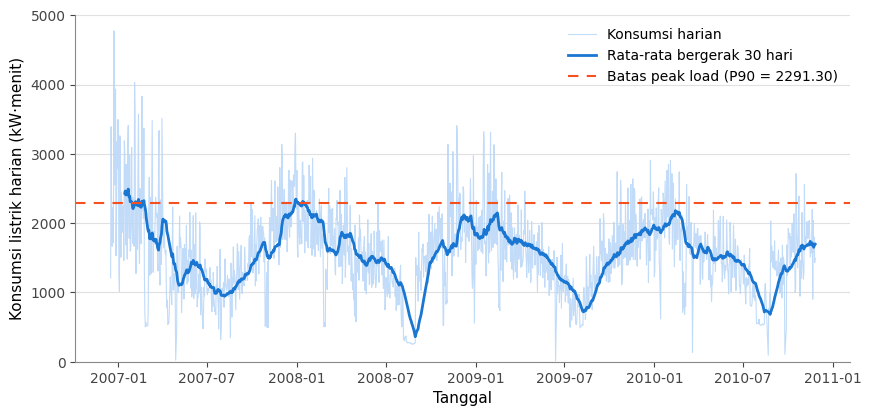

In [17]:
# ==========================================
# TIME SERIES & TREN MUSIMAN (TEMA LAPORAN)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt

# Persiapan Data
data_utama['date'] = pd.to_datetime(data_utama['date'])
batas_lonjakan = data_utama['pemakaian_listrik'].quantile(0.90)

# Mengatur Tema Sesuai Laporan PDF (Terang & Bersih)
plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 4.5))

# Plot Garis
ax.plot(data_utama['date'], data_utama['pemakaian_listrik'], color='#bbd8f8', linewidth=0.8, alpha=0.9, label='Konsumsi harian')
rata_bergerak_30 = data_utama['pemakaian_listrik'].rolling(window=30).mean()
ax.plot(data_utama['date'], rata_bergerak_30, color='#1976D2', linewidth=2, label='Rata-rata bergerak 30 hari')
ax.axhline(batas_lonjakan, color='#F4511E', linestyle='--', linewidth=1.5, dashes=(5, 4), label=f'Batas peak load (P90 = {batas_lonjakan:.2f})')

# Pengaturan Sumbu & Tampilan
ax.set_xlabel("Tanggal", fontname="Times New Roman", fontsize=11)
ax.set_ylabel("Konsumsi listrik harian (kW·menit)", fontname="Times New Roman", fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#888888')
ax.spines['bottom'].set_color('#888888')
ax.tick_params(colors='#444444')
ax.grid(axis='y', color='#e0e0e0', linestyle='-')
ax.set_ylim(0, 5000)

plt.legend(frameon=False, prop={'family': 'Times New Roman', 'size': 10})
plt.show()

# **Pola Konsumsi & Peluang Berdasarkan Bulan**

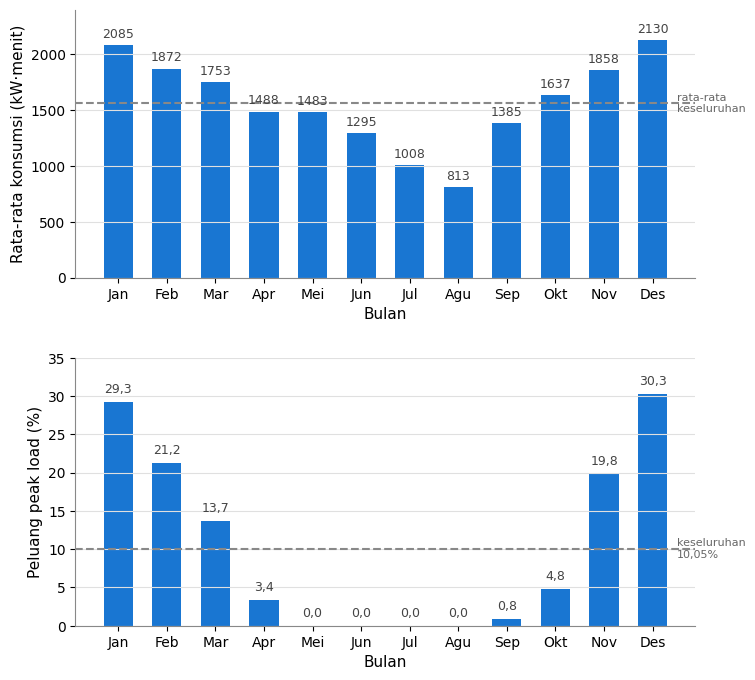

In [18]:
# ==========================================
# ANALISIS POLA BULANAN (TEMA LAPORAN)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

df_bulan = data_utama.groupby('bulan').agg(rata_konsumsi=('pemakaian_listrik', 'mean'), peluang_peak=('peak', 'mean')).reset_index()
df_bulan['peluang_peak'] = df_bulan['peluang_peak'] * 100
df_bulan['nama_bulan'] = singkatan_bulan

plt.style.use('default')
fig, axes = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={'hspace': 0.3})

# --- Chart Atas: Rata-rata Konsumsi ---
axes[0].bar(df_bulan['nama_bulan'], df_bulan['rata_konsumsi'], color='#1976D2', width=0.6)
rata_keseluruhan = data_utama['pemakaian_listrik'].mean()
axes[0].axhline(rata_keseluruhan, color='#888888', linestyle='--', linewidth=1.5)
axes[0].text(11.5, rata_keseluruhan, 'rata-rata\nkeseluruhan', va='center', ha='left', fontsize=8, color='#666666', fontname="Times New Roman")

for index, value in enumerate(df_bulan['rata_konsumsi']):
    axes[0].text(index, value + 40, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='#444')

axes[0].set_ylabel("Rata-rata konsumsi (kW·menit)", fontname="Times New Roman", fontsize=11)
axes[0].set_xlabel("Bulan", fontname="Times New Roman", fontsize=11)
axes[0].set_ylim(0, 2400)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].spines['left'].set_color('#888888')
axes[0].spines['bottom'].set_color('#888888')
axes[0].grid(axis='y', color='#e0e0e0', linestyle='-')

# --- Chart Bawah: Peluang Peak Load ---
axes[1].bar(df_bulan['nama_bulan'], df_bulan['peluang_peak'], color='#1976D2', width=0.6)
peluang_keseluruhan = (data_utama['peak'].mean()) * 100
axes[1].axhline(peluang_keseluruhan, color='#888888', linestyle='--', linewidth=1.5)
axes[1].text(11.5, peluang_keseluruhan, 'keseluruhan\n10,05%', va='center', ha='left', fontsize=8, color='#666666', fontname="Times New Roman")

for index, value in enumerate(df_bulan['peluang_peak']):
    teks_peluang = f"{value:.1f}".replace('.', ',')
    axes[1].text(index, value + 0.8, teks_peluang, ha='center', va='bottom', fontsize=9, color='#444')

axes[1].set_ylabel("Peluang peak load (%)", fontname="Times New Roman", fontsize=11)
axes[1].set_xlabel("Bulan", fontname="Times New Roman", fontsize=11)
axes[1].set_ylim(0, 35)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('#888888')
axes[1].spines['bottom'].set_color('#888888')
axes[1].grid(axis='y', color='#e0e0e0', linestyle='-')

plt.show()

## **Pola Hari**

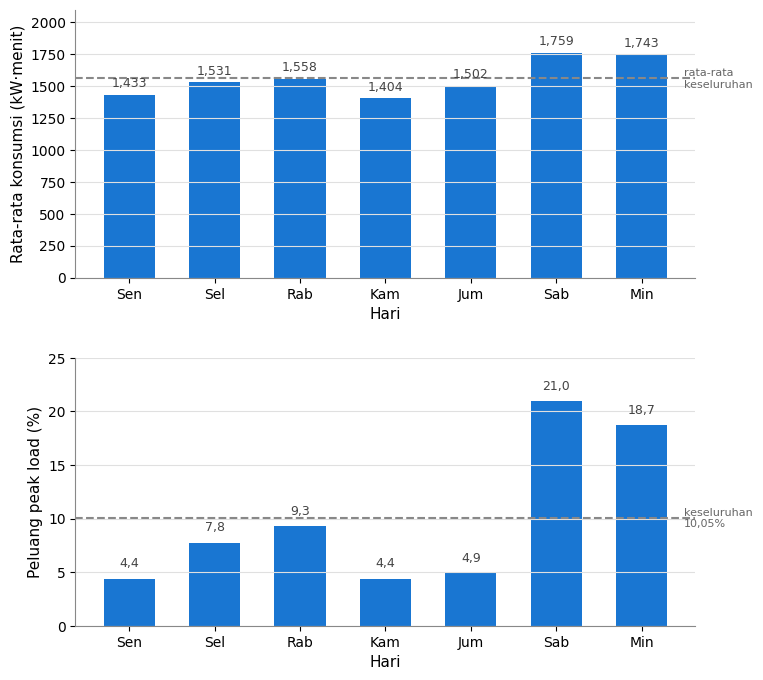

In [ ]:
# ==========================================
#ANALISIS POLA HARI (TEMA LAPORAN)
# ==========================================
import matplotlib.pyplot as plt
import pandas as pd

# --- PERSIAPAN DATA HARI (MEMPERBAIKI ERROR) ---
singkatan_hari = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
nomor_hari = data_utama['date'].dt.dayofweek
data_utama['hari_singkat'] = nomor_hari.map(lambda i: singkatan_hari[i])
data_utama['jenis_hari'] = nomor_hari.map(lambda i: 'Akhir pekan' if i >= 5 else 'Hari kerja')
# -----------------------------------------------

# Menghitung rata-rata dan peluang
df_hari = data_utama.groupby('hari_singkat').agg(rata_konsumsi=('pemakaian_listrik', 'mean'), peluang_peak=('peak', 'mean')).reindex(singkatan_hari).reset_index()
df_hari['peluang_peak'] = df_hari['peluang_peak'] * 100

plt.style.use('default')
fig2, axes2 = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={'hspace': 0.3})

# --- Chart Atas: Rata-rata Konsumsi ---
axes2[0].bar(df_hari['hari_singkat'], df_hari['rata_konsumsi'], color='#1976D2', width=0.6)
rata_keseluruhan = data_utama['pemakaian_listrik'].mean()
axes2[0].axhline(rata_keseluruhan, color='#888888', linestyle='--', linewidth=1.5)
axes2[0].text(6.5, rata_keseluruhan, 'rata-rata\nkeseluruhan', va='center', ha='left', fontsize=8, color='#666666', fontname="Times New Roman")

for index, value in enumerate(df_hari['rata_konsumsi']):
    teks_rata = f"{value/1000:.3f}".replace('.', ',')
    axes2[0].text(index, value + 40, teks_rata, ha='center', va='bottom', fontsize=9, color='#444')

axes2[0].set_ylabel("Rata-rata konsumsi (kW·menit)", fontname="Times New Roman", fontsize=11)
axes2[0].set_xlabel("Hari", fontname="Times New Roman", fontsize=11)
axes2[0].set_ylim(0, 2100)
axes2[0].spines['top'].set_visible(False)
axes2[0].spines['right'].set_visible(False)
axes2[0].spines['left'].set_color('#888888')
axes2[0].spines['bottom'].set_color('#888888')
axes2[0].grid(axis='y', color='#e0e0e0', linestyle='-')

# --- Chart Bawah: Peluang Peak Load ---
axes2[1].bar(df_hari['hari_singkat'], df_hari['peluang_peak'], color='#1976D2', width=0.6)
peluang_keseluruhan = (data_utama['peak'].mean()) * 100
axes2[1].axhline(peluang_keseluruhan, color='#888888', linestyle='--', linewidth=1.5)
axes2[1].text(6.5, peluang_keseluruhan, 'keseluruhan\n10,05%', va='center', ha='left', fontsize=8, color='#666666', fontname="Times New Roman")

for index, value in enumerate(df_hari['peluang_peak']):
    teks_peluang = f"{value:.1f}".replace('.', ',')
    axes2[1].text(index, value + 0.8, teks_peluang, ha='center', va='bottom', fontsize=9, color='#444')

axes2[1].set_ylabel("Peluang peak load (%)", fontname="Times New Roman", fontsize=11)
axes2[1].set_xlabel("Hari", fontname="Times New Roman", fontsize=11)
axes2[1].set_ylim(0, 25)
axes2[1].spines['top'].set_visible(False)
axes2[1].spines['right'].set_visible(False)
axes2[1].spines['left'].set_color('#888888')
axes2[1].spines['bottom'].set_color('#888888')
axes2[1].grid(axis='y', color='#e0e0e0', linestyle='-')

plt.show()

# **DASHBOR TAMPILAN ANALYSIS DATA**

,date,suhu_maksimal,curah_hujan,pemakaian_listrik,hari,jenis_hari,musim,peak
0,2006-12-16,10.6,0.0,1209.176,Sabtu,Akhir pekan,Dingin,False
1,2006-12-17,13.3,0.0,3390.460,Minggu,Akhir pekan,Dingin,True
2,2006-12-18,15.0,0.0,2203.826,Senin,Hari kerja,Dingin,False
3,2006-12-19,7.2,0.0,1666.194,Selasa,Hari kerja,Dingin,False
4,2006-12-20,7.2,0.0,2225.748,Rabu,Hari kerja,Dingin,False
...,...,...,...,...,...,...,...,...
1428,2010-11-22,18.3,0.0,2041.536,Senin,Hari kerja,Gugur,False
1429,2010-11-23,16.1,0.0,1577.536,Selasa,Hari kerja,Gugur,False
1430,2010-11-24,10.0,0.0,1796.248,Rabu,Hari kerja,Gugur,False
1431,2010-11-25,7.8,1.5,1431.164,Kamis,Hari kerja,Gugur,False



[!] TOTAL RECORDS FOUND: 1433 ROWS



,pemakaian_listrik,suhu_maksimal,curah_hujan
count,1433.000000,1433.000000,1433.000000
mean,1561.078061,17.187509,3.800488
std,606.819667,10.136415,10.973436
min,14.218000,-8.900000,0.000000
25%,1165.700000,8.900000,0.000000
50%,1542.650000,17.800000,0.000000
75%,1893.608000,26.100000,1.300000
max,4773.386000,39.400000,192.300000


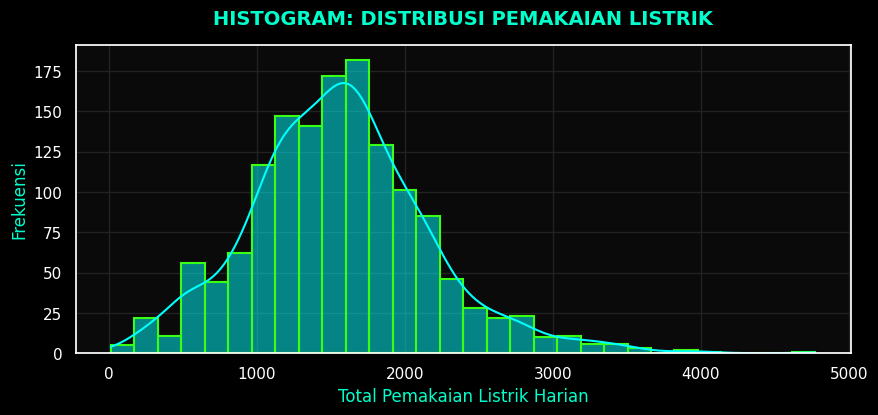

[*] THRESHOLD 'PEAK LOAD' (Top 10%) = 2291.30



,Kondisi Cuaca,Peluang Peak Load (%)
0,Hari Hujan,11.600000
1,Hari Cerah,9.217578


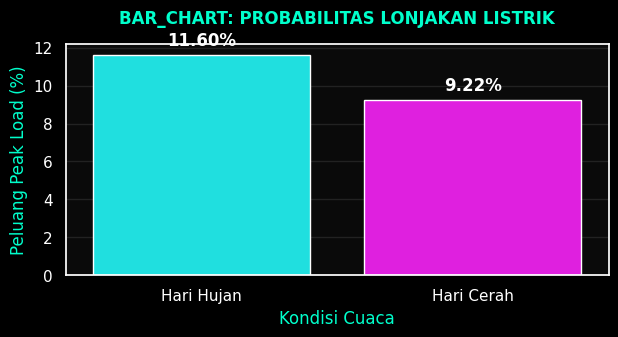

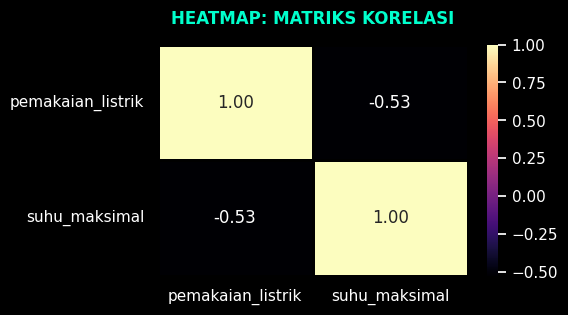

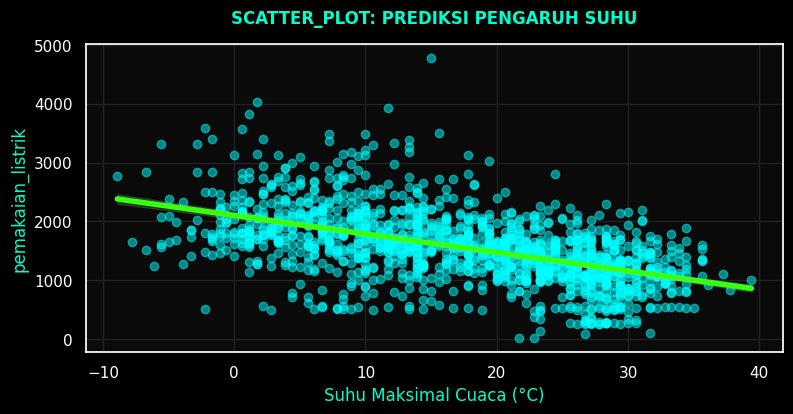

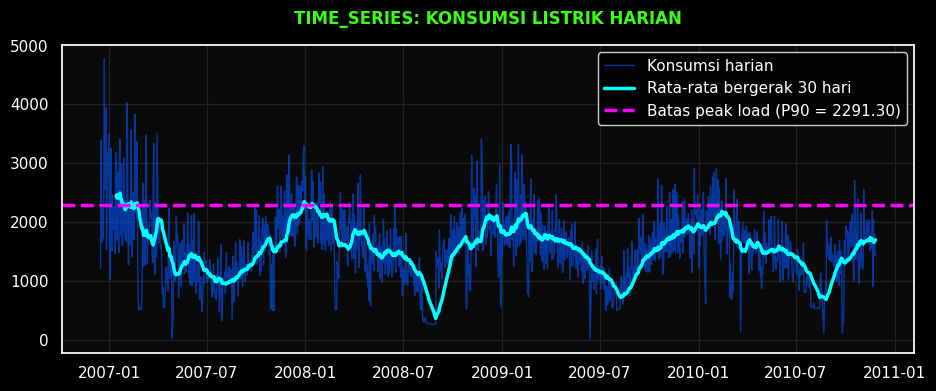

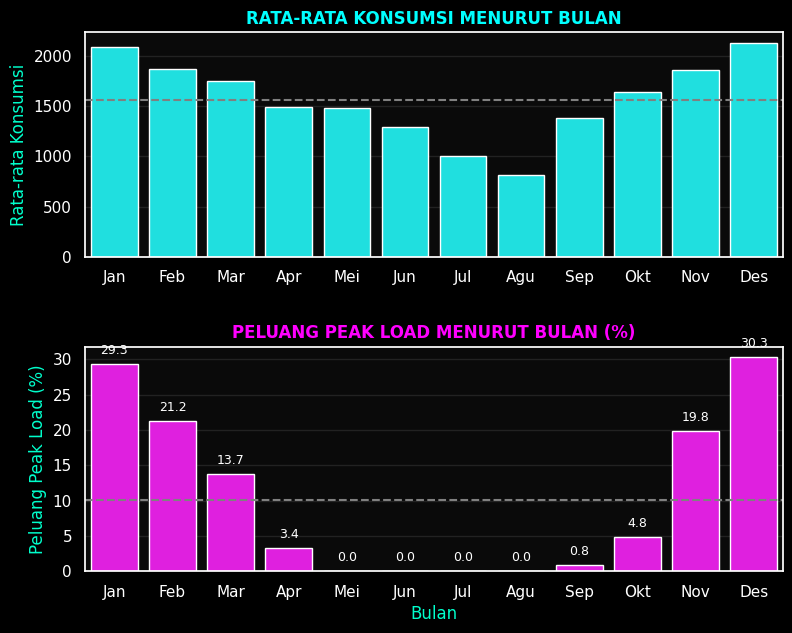

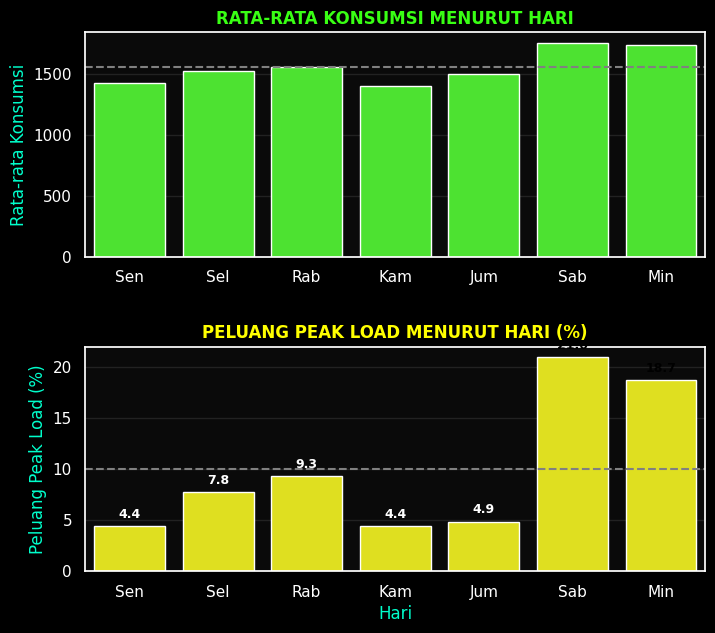

In [19]:
# =========================================================================
# SYSTEM DASHBOARD ULTIMATE: CUACA & POLA WAKTU (HACKER VIBE)
# =========================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, HTML
from google.colab import data_table
import warnings
warnings.filterwarnings('ignore') # Menyembunyikan peringatan agar rapi

# --- 1. LOAD DATA & PREPARATION ---
nama_file = "3TIA_Kelompok10_Electricity Consumption.xlsx"
try:
    data_utama = pd.read_excel(nama_file, sheet_name=0)
    data_utama = data_utama.rename(columns={'daily_consumption': 'pemakaian_listrik', 'TMAX': 'suhu_maksimal', 'PRCP': 'curah_hujan'})

    # Persiapan Variabel Waktu
    data_utama['date'] = pd.to_datetime(data_utama['date'])
    batas_lonjakan = data_utama['pemakaian_listrik'].quantile(0.90)
    data_utama['peak'] = data_utama['pemakaian_listrik'] >= batas_lonjakan

    nama_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
    singkatan_hari = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
    singkatan_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

    nomor_hari = data_utama['date'].dt.dayofweek
    data_utama['hari'] = nomor_hari.map(lambda i: nama_hari[i])
    data_utama['hari_singkat'] = nomor_hari.map(lambda i: singkatan_hari[i])
    data_utama['jenis_hari'] = nomor_hari.map(lambda i: 'Akhir pekan' if i >= 5 else 'Hari kerja')

    data_utama['bulan'] = data_utama['date'].dt.month
    data_utama['nama_bulan'] = data_utama['bulan'].map(lambda i: singkatan_bulan[i-1])

    musim = {12: 'Dingin', 1: 'Dingin', 2: 'Dingin', 3: 'Semi', 4: 'Semi', 5: 'Semi',
             6: 'Panas', 7: 'Panas', 8: 'Panas', 9: 'Gugur', 10: 'Gugur', 11: 'Gugur'}
    data_utama['musim'] = data_utama['bulan'].map(musim)
except Exception as e:
    print("ERROR: File tidak ditemukan. Pastikan file Excel sudah di-upload!")

# --- SETTING TEMA GRAFIK HACKER (DARK & NEON) ---
plt.style.use('dark_background')
sns.set_theme(style="darkgrid", rc={
    "axes.facecolor": "#0a0a0a", "figure.facecolor": "#000000", "grid.color": "#222222",
    "text.color": "#00ffcc", "xtick.color": "#ffffff", "ytick.color": "#ffffff", "axes.labelcolor": "#00ffcc"
})

neon_cyan = '#00ffff'
neon_green = '#39ff14'
neon_pink = '#ff00ff'
neon_yellow = '#ffff00'
neon_blue = '#0055ff'

# --- HEADER DASHBOARD ---
display(HTML("""
<div style='background-color: #050505; padding: 20px; border-left: 6px solid #39ff14; border-radius: 5px; margin-bottom: 20px; font-family: "Courier New", Courier, monospace;'>
    <h1 style='color: #39ff14; margin:0; text-shadow: 0px 0px 5px #39ff14;'>>_ SYSTEM_DASHBOARD: KELOMPOK 10</h1>
    <h3 style='color: #00ffff; margin:10px 0 0 0;'>[JUDUL]: Analisis Probabilitas Terjadinya Lonjakan Beban Listrik (Peak Load) Berdasarkan Waktu dan Cuaca</h3>
    <p style='color: #aaaaaa; margin-top:5px;'>Status: <span style='color: #39ff14;'>ALL SYSTEMS ONLINE & SYNCHRONIZED</span></p>
</div>
"""))

# ==========================================
# [1] PREVIEW DATASET
# ==========================================
display(HTML("<h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[1] DB_QUERY: SELECT * FROM dataset_listrik;</h2>"))
tabel_interaktif = data_table.DataTable(data_utama[['date', 'suhu_maksimal', 'curah_hujan', 'pemakaian_listrik', 'hari', 'jenis_hari', 'musim', 'peak']], num_rows_per_page=5)
display(tabel_interaktif)
print(f"\n[!] TOTAL RECORDS FOUND: {len(data_utama)} ROWS\n")

# ==========================================
# [2] STATISTIKA DESKRIPTIF
# ==========================================
display(HTML("<br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[2] EXECUTE: STATISTIKA_DESKRIPTIF</h2>"))
tabel_ringkasan = data_utama[['pemakaian_listrik', 'suhu_maksimal', 'curah_hujan']].describe()
display(tabel_ringkasan)

plt.figure(figsize=(10, 4))
sns.histplot(data_utama['pemakaian_listrik'], bins=30, kde=True, color=neon_cyan, edgecolor=neon_green, linewidth=1.5)
plt.title("HISTOGRAM: DISTRIBUSI PEMAKAIAN LISTRIK", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Pemakaian Listrik Harian")
plt.ylabel("Frekuensi")
plt.show()

# ==========================================
# [3] DISTRIBUSI PROBABILITAS (CUACA)
# ==========================================
display(HTML("<br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[3] EXECUTE: PROBABILITAS_CUACA</h2>"))
hari_hujan = data_utama[data_utama['curah_hujan'] > 0]
hari_cerah = data_utama[data_utama['curah_hujan'] == 0]
pel_hujan = (len(hari_hujan[hari_hujan['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_hujan)) * 100
pel_cerah = (len(hari_cerah[hari_cerah['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_cerah)) * 100

tabel_peluang = pd.DataFrame({'Kondisi Cuaca': ['Hari Hujan', 'Hari Cerah'], 'Peluang Peak Load (%)': [pel_hujan, pel_cerah]})
print(f"[*] THRESHOLD 'PEAK LOAD' (Top 10%) = {batas_lonjakan:.2f}\n")
display(tabel_peluang)

plt.figure(figsize=(7, 3))
sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, palette=[neon_cyan, neon_pink])
for index, value in enumerate(tabel_peluang['Peluang Peak Load (%)']):
    plt.text(index, value + 0.3, f'{value:.2f}%', ha='center', va='bottom', fontweight='bold', color='#ffffff')
plt.title("BAR_CHART: PROBABILITAS LONJAKAN LISTRIK", fontweight='bold', pad=15)
plt.show()

# ==========================================
# [4] STATISTIKA INFERENSIAL (CUACA)
# ==========================================
display(HTML("<br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[4] EXECUTE: STATISTIKA_INFERENSIAL</h2>"))
tabel_korelasi = data_utama[['pemakaian_listrik', 'suhu_maksimal']].corr()
plt.figure(figsize=(5, 3))
sns.heatmap(tabel_korelasi, annot=True, cmap='magma', fmt=".2f", linewidths=1, linecolor='black')
plt.title("HEATMAP: MATRIKS KORELASI", fontweight='bold', pad=15)
plt.show()

plt.figure(figsize=(9, 4))
sns.regplot(x='suhu_maksimal', y='pemakaian_listrik', data=data_utama, scatter_kws={'alpha':0.5, 'color':neon_cyan}, line_kws={'color':neon_green, 'linewidth':4})
plt.title("SCATTER_PLOT: PREDIKSI PENGARUH SUHU", fontweight='bold', pad=15)
plt.xlabel("Suhu Maksimal Cuaca (°C)")
plt.show()

# ==========================================
# [5] ANALISIS POLA WAKTU
# ==========================================
display(HTML("<br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[5] POLA WAKTU DAN PELUANG PEAK LOAD</h2>"))

display(HTML("<h4 style='color: #00ffff;'>-> 5.1. Pola Musiman dan Bulanan (Time Series)</h4>"))
# GRAFIK 1: TIME SERIES
plt.figure(figsize=(11, 4))
plt.plot(data_utama['date'], data_utama['pemakaian_listrik'], color=neon_blue, alpha=0.6, linewidth=1, label='Konsumsi harian')
rata_bergerak_30 = data_utama['pemakaian_listrik'].rolling(window=30).mean()
plt.plot(data_utama['date'], rata_bergerak_30, color=neon_cyan, linewidth=2.5, label='Rata-rata bergerak 30 hari')
plt.axhline(batas_lonjakan, color=neon_pink, linestyle='--', linewidth=2.5, label=f'Batas peak load (P90 = {batas_lonjakan:.2f})')
plt.title("TIME_SERIES: KONSUMSI LISTRIK HARIAN", fontweight='bold', color=neon_green, pad=15)
plt.legend(facecolor='black', edgecolor='white', labelcolor='white')
plt.show()

# GRAFIK 2: POLA BULANAN
df_bulan = data_utama.groupby('bulan').agg(rata_konsumsi=('pemakaian_listrik', 'mean'), peluang_peak=('peak', 'mean')).reset_index()
df_bulan['peluang_peak'] = df_bulan['peluang_peak'] * 100
df_bulan['nama_bulan'] = singkatan_bulan

fig, axes = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={'hspace': 0.4})
sns.barplot(ax=axes[0], x='nama_bulan', y='rata_konsumsi', data=df_bulan, color=neon_cyan)
axes[0].axhline(data_utama['pemakaian_listrik'].mean(), color='gray', linestyle='--')
axes[0].set_title("RATA-RATA KONSUMSI MENURUT BULAN", color=neon_cyan, fontweight='bold')
axes[0].set_ylabel("Rata-rata Konsumsi")
axes[0].set_xlabel("")

sns.barplot(ax=axes[1], x='nama_bulan', y='peluang_peak', data=df_bulan, color=neon_pink)
axes[1].axhline((data_utama['peak'].mean())*100, color='gray', linestyle='--')
for index, value in enumerate(df_bulan['peluang_peak']):
    axes[1].text(index, value + 1, f'{value:.1f}', ha='center', va='bottom', color='white', fontsize=9)
axes[1].set_title("PELUANG PEAK LOAD MENURUT BULAN (%)", color=neon_pink, fontweight='bold')
axes[1].set_ylabel("Peluang Peak Load (%)")
axes[1].set_xlabel("Bulan")
plt.show()

display(HTML("<br><h4 style='color: #00ffff;'>-> 5.2. Pola Hari dalam Minggu</h4>"))
# GRAFIK 3: POLA HARIAN
df_hari = data_utama.groupby('hari_singkat').agg(rata_konsumsi=('pemakaian_listrik', 'mean'), peluang_peak=('peak', 'mean')).reindex(singkatan_hari).reset_index()
df_hari['peluang_peak'] = df_hari['peluang_peak'] * 100

fig2, axes2 = plt.subplots(2, 1, figsize=(8, 7), gridspec_kw={'hspace': 0.4})
sns.barplot(ax=axes2[0], x='hari_singkat', y='rata_konsumsi', data=df_hari, color=neon_green)
axes2[0].axhline(data_utama['pemakaian_listrik'].mean(), color='gray', linestyle='--')
axes2[0].set_title("RATA-RATA KONSUMSI MENURUT HARI", color=neon_green, fontweight='bold')
axes2[0].set_ylabel("Rata-rata Konsumsi")
axes2[0].set_xlabel("")

sns.barplot(ax=axes2[1], x='hari_singkat', y='peluang_peak', data=df_hari, color=neon_yellow)
axes2[1].axhline((data_utama['peak'].mean())*100, color='gray', linestyle='--')
for index, value in enumerate(df_hari['peluang_peak']):
    axes2[1].text(index, value + 0.5, f'{value:.1f}', ha='center', va='bottom', color='black' if value > 10 else 'white', fontweight='bold', fontsize=9)
axes2[1].set_title("PELUANG PEAK LOAD MENURUT HARI (%)", color=neon_yellow, fontweight='bold')
axes2[1].set_ylabel("Peluang Peak Load (%)")
axes2[1].set_xlabel("Hari")
plt.show()

# CHI-SQUARE OUTPUT
tabel_jenis_hari = pd.crosstab(data_utama['jenis_hari'], data_utama['peak'])
chi2_hari, p_hari, db_hari, _ = stats.chi2_contingency(tabel_jenis_hari, correction=False)
display(HTML(f"""
<div style='background-color: #111; padding: 15px; border-left: 4px solid #ffff00; border-radius: 4px; margin-top: 5px; font-family: sans-serif; color: #ddd;'>
    <strong style='color: #ffff00;'>[UJI CHI-SQUARE: HARI KERJA VS AKHIR PEKAN]:</strong> Uji chi-square menghasilkan χ² = <b>{chi2_hari:.2f}</b> dengan derajat bebas <b>{db_hari}</b> dan nilai p lebih kecil dari 0,001, sehingga terbukti secara signifikan jenis hari berkaitan dengan kejadian peak load.
</div>
"""))